# Prédire l'échec scolaire en mathématiques : un système d'alerte précoce par Machine Learning

**Jeu de données :** *Student Performance* (Cortez & Silva, 2008), 395 élèves de deux lycées portugais, cours de mathématiques (`student-mat.csv`).

**Plan**
0. Positionnement : IA, ML, DL
1. Formulation du problème et hypothèses
2. Phase d'exploration
3. Phase de feature engineering (+ une analyse non supervisée)
4. Phase d'apprentissage
5. Phase de réglage des hyperparamètres
6. Évaluation finale et interprétation
7. Analyses complémentaires : régression, abandons et fuite de données, apport du portugais, équité, généralisation, parcimonie
8. Conclusion et suite du projet

## 0. Positionnement : IA, ML, DL

L'**intelligence artificielle (IA)** regroupe l'ensemble des méthodes permettant à une machine de réaliser des tâches qui semblent demander de l'intelligence. Le **Machine Learning (ML)** en est un sous-ensemble : au lieu d'écrire des règles à la main (« si l'élève a redoublé et s'absente beaucoup, alors il est à risque »), on laisse un algorithme **apprendre ces règles à partir d'exemples**. Le **Deep Learning (DL)** est lui-même un sous-ensemble du ML, fondé sur des réseaux de neurones profonds.

Ici nous faisons du ML classique et **pas** de Deep Learning, pour une raison simple : nous avons **395 lignes et 30 variables tabulaires**. Les réseaux de neurones profonds brillent sur de très gros volumes de données non structurées (images, texte, son). Sur un petit tableau, ils sur-apprendraient (overfitting) sans battre des modèles plus simples et plus interprétables, ce qui est essentiel quand la décision concerne des élèves.

## 1. Formulation du problème et hypothèses

### Le cas d'usage
Un lycée veut **repérer le plus tôt possible les élèves qui risquent d'échouer en mathématiques**, afin de leur proposer du soutien (tutorat, suivi, contact avec la famille) avant qu'il ne soit trop tard.

### Formulation en problème de ML
- **Type d'apprentissage : supervisé**, car on dispose de la « bonne réponse » (la note finale G3) pour chaque élève du passé.
- **Tâche : classification binaire.** Au Portugal, la moyenne est à 10/20. On définit la cible `echec = 1 si G3 < 10`, sinon 0.
  On aurait pu faire une régression sur G3 (0 à 20), mais la décision réelle de l'école est binaire (aider ou non), et la classification rend les erreurs plus faciles à interpréter.
- **Trois scénarios selon le moment de l'année** où l'on fait la prédiction :

| Scénario | Moment | Variables disponibles |
|---|---|---|
| **A** | Rentrée scolaire | Profil de l'élève uniquement (famille, habitudes, passé scolaire) |
| **B** | Après le 1er trimestre | Profil + note G1 |
| **C** | Après le 2e trimestre | Profil + G1 + G2 |

Le scénario A est le plus utile (on agit tôt) mais aussi le plus difficile. Le scénario C est presque trivial mais arrive trop tard pour agir.

### Choix de la métrique
Les deux erreurs n'ont pas le même coût :
- **Faux négatif** (élève en difficulté non détecté) : il ne reçoit pas d'aide et échoue. **Coût élevé.**
- **Faux positif** (élève signalé à tort) : il reçoit un soutien dont il n'avait pas besoin. Coût faible.

On privilégie donc le **rappel (recall) sur la classe « échec »**, en surveillant la précision pour ne pas signaler tout le monde. On résume le compromis par le **F1-score** et on regarde aussi l'**AUC ROC**, indépendante du seuil de décision.

### Hypothèses de travail
- **H1** : les **échecs passés** (`failures`) sont le meilleur prédicteur au sein du profil (scénario A).
- **H2** : dès qu'elles sont disponibles, les **notes intermédiaires G1 et G2** écrasent toutes les autres variables.
- **H3** : le **contexte familial** (éducation des parents, soutien) a un effet réel mais modéré.
- **H4** : les **habitudes de vie** (sorties, alcool) sont associées négativement à la réussite.
- **H5** : l'ambition de faire des **études supérieures** (`higher`) est associée à la réussite.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV, validation_curve)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
                             recall_score, precision_score, f1_score, roc_auc_score)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid", palette="Set2")
SEED = 42
df = pd.read_csv("data/student-mat.csv", sep=";")
print(df.shape)
df.head()

(395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 2. Phase d'exploration

### 2.1 Qualité des données

In [2]:
print("Valeurs manquantes :", df.isna().sum().sum())
print("Doublons :", df.duplicated().sum())
df.describe().T[["mean", "std", "min", "max"]].round(2)

Valeurs manquantes : 0
Doublons : 0


,mean,std,min,max
age,16.70,1.28,15.0,22.0
Medu,2.75,1.09,0.0,4.0
Fedu,2.52,1.09,0.0,4.0
traveltime,1.45,0.70,1.0,4.0
studytime,2.04,0.84,1.0,4.0
failures,0.33,0.74,0.0,3.0
famrel,3.94,0.90,1.0,5.0
freetime,3.24,1.00,1.0,5.0
goout,3.11,1.11,1.0,5.0
Dalc,1.48,0.89,1.0,5.0


Aucune valeur manquante ni doublon : le jeu de données est propre. Les variables sont un mélange de binaires, de nominales, d'ordinales (échelles 1 à 5) et de numériques (âge, absences, notes).

### 2.2 La variable cible

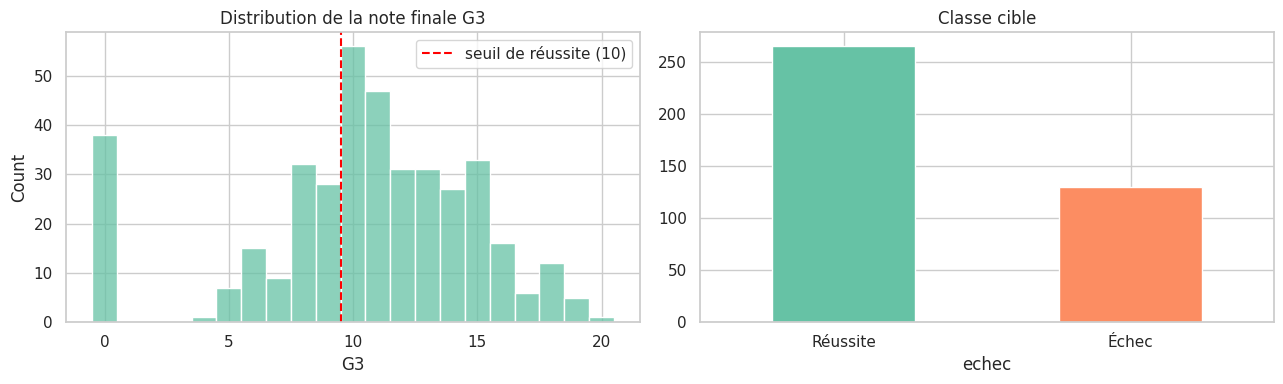

echec
0    0.671
1    0.329
Name: proportion, dtype: float64


In [3]:
df["echec"] = (df["G3"] < 10).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["G3"], bins=21, discrete=True, ax=ax[0])
ax[0].axvline(9.5, color="red", ls="--", label="seuil de réussite (10)")
ax[0].set_title("Distribution de la note finale G3"); ax[0].legend()
df["echec"].map({0: "Réussite", 1: "Échec"}).value_counts().plot.bar(ax=ax[1], color=["#66c2a5", "#fc8d62"])
ax[1].set_title("Classe cible"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
print(df["echec"].value_counts(normalize=True).round(3))

**Observations**
- Environ **33 % d'élèves en échec** : les classes sont **déséquilibrées** mais pas extrêmement. Un modèle « idiot » qui prédit toujours « réussite » obtiendrait déjà 67 % d'accuracy, d'où l'intérêt de regarder le rappel et le F1 plutôt que l'accuracy.
- Il existe un **pic anormal à G3 = 0** : une note de 0 est très rare en conditions normales.

In [4]:
zeros = df[df["G3"] == 0]
print(f"{len(zeros)} élèves ont G3 = 0")
print("Parmi eux, absences moyennes :", zeros["absences"].mean().round(2), "vs", df[df.G3 > 0]["absences"].mean().round(2), "pour les autres")
print("G2 moyen de ces élèves :", zeros["G2"].mean().round(2))

38 élèves ont G3 = 0
Parmi eux, absences moyennes : 0.0 vs 6.32 pour les autres
G2 moyen de ces élèves : 4.66


Ces élèves ont **0 absence** alors qu'ils ont souvent eu des notes non nulles en G1/G2. C'est incohérent avec un élève qui aurait simplement « tout raté » : il s'agit très probablement d'élèves **qui ont abandonné ou ne se sont pas présentés à l'examen final** (et dont les absences n'ont plus été comptées). C'est un point typique où il faudrait **demander l'information métier** à l'établissement (voir conclusion). Nous les gardons dans la classe « échec », car du point de vue de l'école, un abandon est bien un échec qu'on aurait voulu prévenir.

### 2.3 Relations entre les variables et la cible

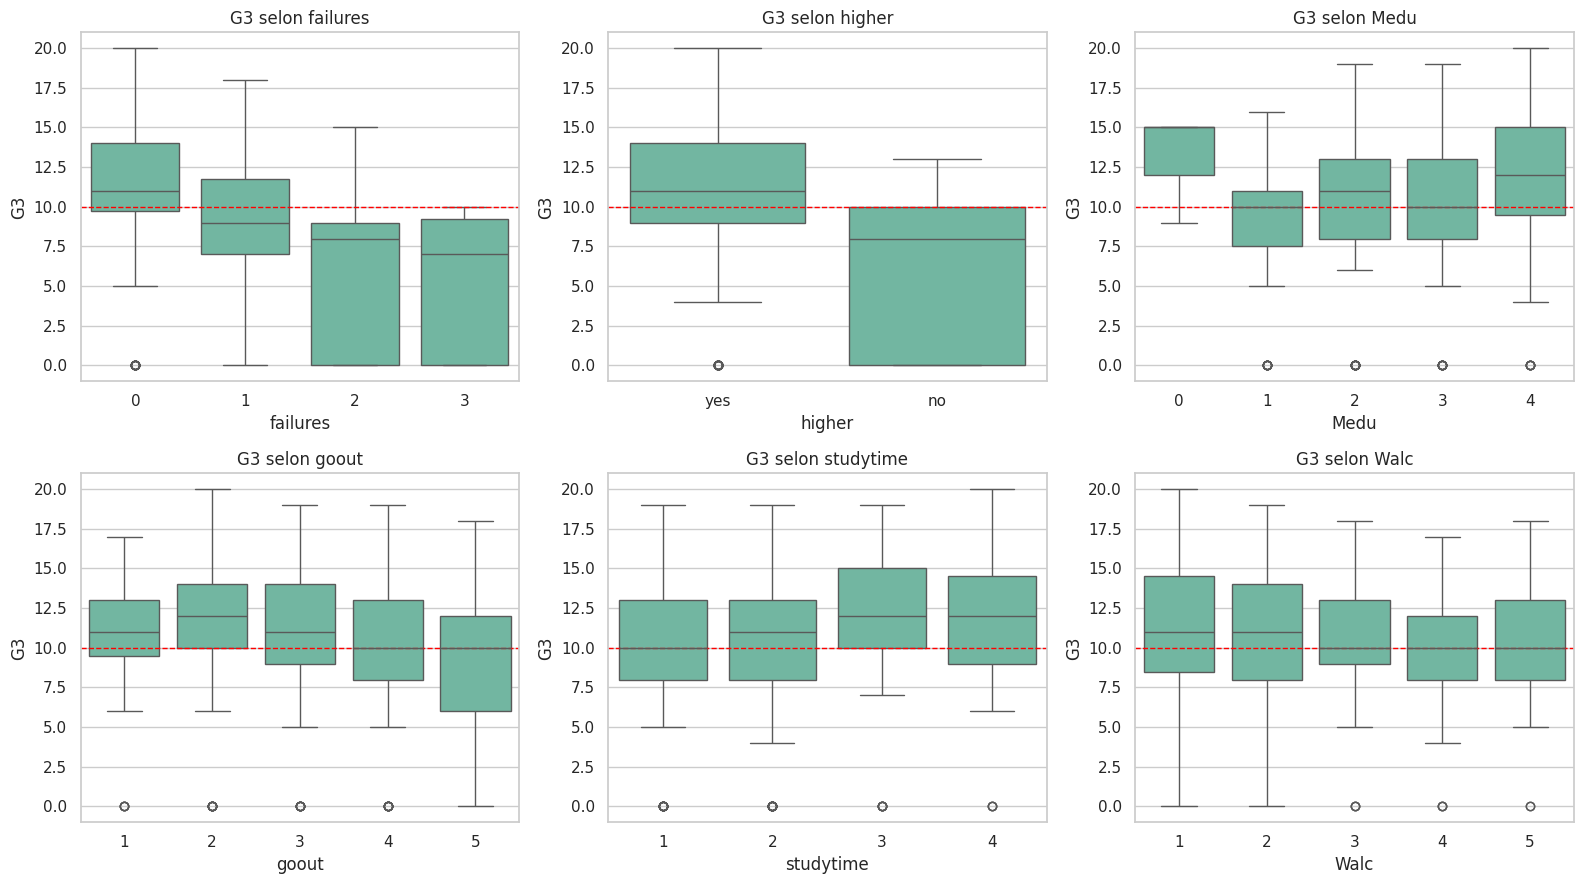

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, ["failures", "higher", "Medu", "goout", "studytime", "Walc"]):
    sns.boxplot(data=df, x=col, y="G3", ax=ax)
    ax.axhline(10, color="red", ls="--", lw=1)
    ax.set_title(f"G3 selon {col}")
plt.tight_layout(); plt.show()

**Lecture des box plots au regard des hypothèses**
- **H1 confirmée visuellement** : la note médiane chute nettement dès 1 échec passé, et passe sous 10 à partir de 2 ou 3 échecs.
- **H5 confirmée** : les élèves qui ne veulent pas faire d'études supérieures (`higher = no`, peu nombreux) ont une médiane sous la moyenne.
- **H3 partiellement** : une mère très diplômée (`Medu = 4`) va de pair avec de meilleures notes, mais la dispersion reste forte.
- **H4 nuancée** : les élèves qui sortent énormément (`goout = 5`) réussissent moins bien, mais l'effet de l'alcool du week-end (`Walc`) est faible et bruité.
- Le temps d'étude (`studytime`) a un effet positif mais modeste.

### 2.4 Corrélations

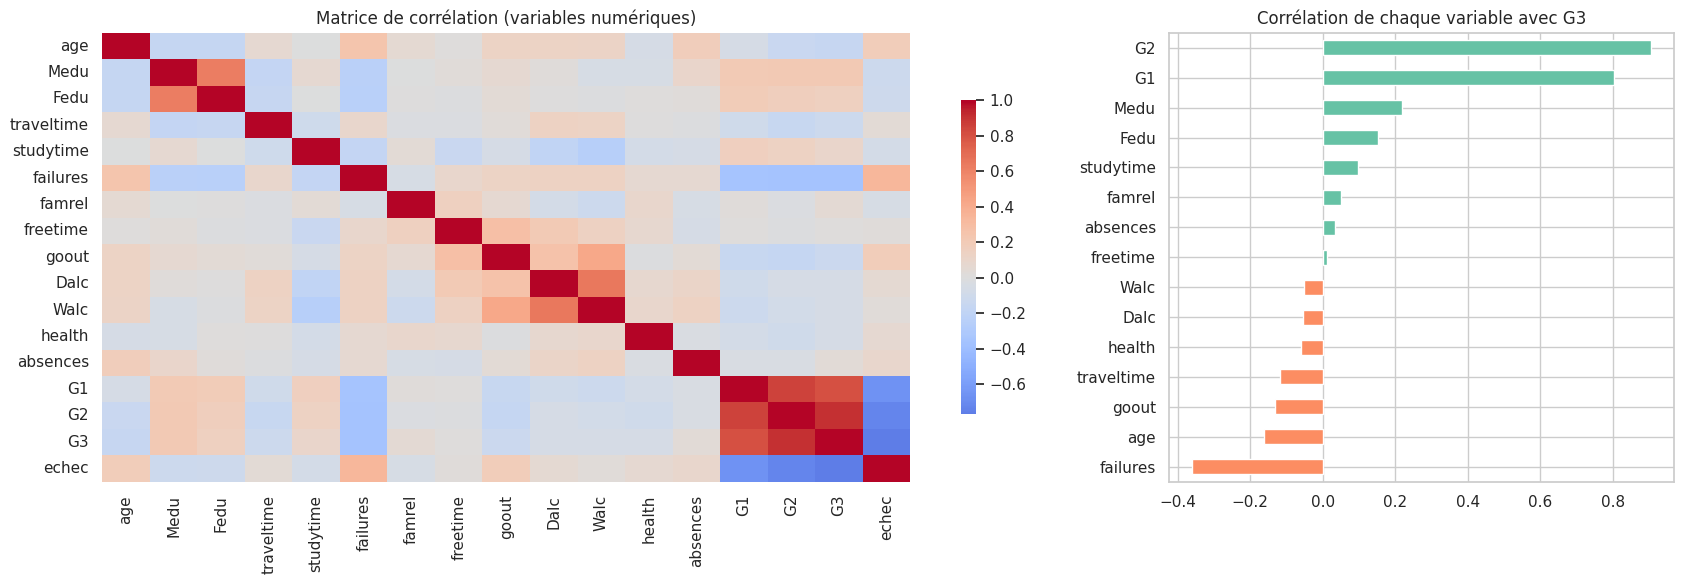

In [6]:
num = df.select_dtypes("number")
fig, ax = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [2, 1]})
sns.heatmap(num.corr(), cmap="coolwarm", center=0, ax=ax[0], cbar_kws={"shrink": .7})
ax[0].set_title("Matrice de corrélation (variables numériques)")
c = num.corr()["G3"].drop(["G3", "echec"]).sort_values()
c.plot.barh(ax=ax[1], color=np.where(c > 0, "#66c2a5", "#fc8d62"))
ax[1].set_title("Corrélation de chaque variable avec G3")
plt.tight_layout(); plt.show()

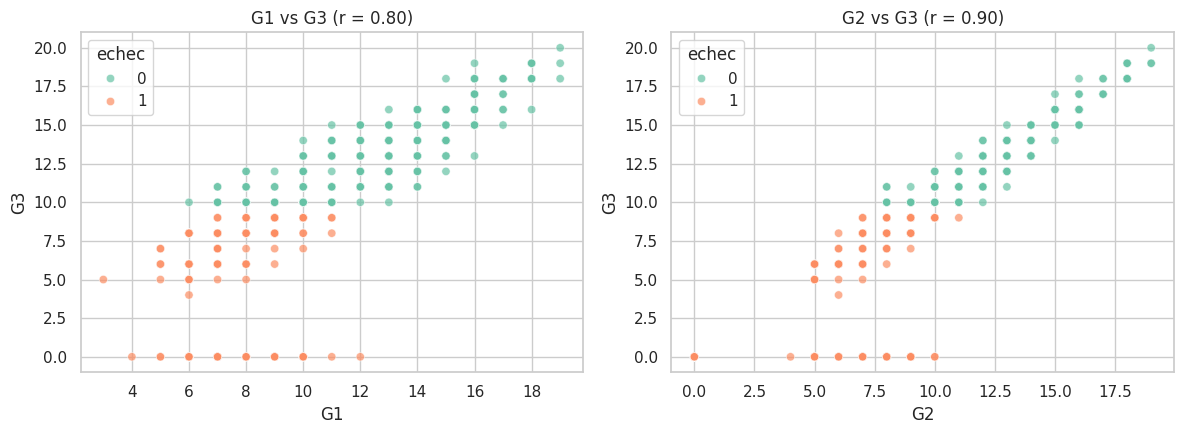

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, g in zip(ax, ["G1", "G2"]):
    sns.scatterplot(data=df, x=g, y="G3", hue="echec", palette={0: "#66c2a5", 1: "#fc8d62"}, alpha=.7, ax=a)
    a.set_title(f"{g} vs G3 (r = {df[g].corr(df.G3):.2f})")
plt.tight_layout(); plt.show()

**Point clé : corrélation n'est pas causalité, et corrélation forte ne veut pas dire modèle utile.**
- **H2 confirmée** : G1 (r ≈ 0,80) et G2 (r ≈ 0,90) sont extrêmement corrélées à G3. Dans le scénario C, le modèle apprendra en gros « si G2 < 10 alors échec ». Il sera très performant mais **n'apportera presque rien** à l'école : un enseignant le sait déjà en voyant le bulletin.
- Hors notes, les corrélations sont **faibles** (|r| < 0,4). `failures` est la plus forte (r ≈ -0,36), ce qui confirme H1. Prédire l'échec à la rentrée sera donc difficile : il faut s'attendre à des performances modestes dans le scénario A.
- Attention : la corrélation de Pearson ne capte que les relations **linéaires**. Des modèles non linéaires (arbres) peuvent exploiter des interactions invisibles ici.
- Enfin, `Dalc` et `Walc` sont corrélées entre elles, de même que `Medu` et `Fedu` : c'est une redondance à traiter en feature engineering.

## 3. Phase de feature engineering

Le **feature engineering** consiste à transformer les variables brutes en **features** (caractéristiques) plus exploitables par l'algorithme. Voici nos choix et leur justification :

| Transformation | Justification |
|---|---|
| Variables `yes/no` → 0/1 | Les modèles ne manipulent que des nombres |
| Variables nominales (`Mjob`, `Fjob`, `reason`, `guardian`) → **one-hot encoding** | Pas d'ordre naturel entre « teacher » et « health » : un codage 0, 1, 2… inventerait un ordre fictif |
| Échelles ordinales (1 à 5) **gardées en numérique** | L'ordre a un sens (« très bas » < « très haut ») |
| `parents_edu = max(Medu, Fedu)` | Résume le capital scolaire familial, réduit la redondance |
| `alcool = (5·Dalc + 2·Walc) / 7` | Consommation moyenne sur la semaine, fusionne deux variables corrélées |
| `a_deja_echoue = failures > 0` | Les box plots montrent un effet de seuil dès le 1er échec |
| `absences` **exclue des modèles** | Les absences sont comptées **sur toute l'année** : elles ne sont pas connues à la rentrée ni après le 1er trimestre. Les garder serait une **fuite de données** (*data leakage*). On la conserve à part (`log_absences`) pour le démontrer en section 7.2 |
| **Standardisation** (pour la régression logistique uniquement) | Met les variables sur la même échelle ; inutile pour les arbres |

In [8]:
X_all = df.copy()
for c in ["schoolsup", "famsup", "paid", "activities", "nursery", "higher", "internet", "romantic"]:
    X_all[c] = (X_all[c] == "yes").astype(int)
X_all["school"]  = (X_all["school"] == "GP").astype(int)
X_all["sex"]     = (X_all["sex"] == "F").astype(int)
X_all["address"] = (X_all["address"] == "U").astype(int)
X_all["famsize"] = (X_all["famsize"] == "GT3").astype(int)
X_all["Pstatus"] = (X_all["Pstatus"] == "T").astype(int)

X_all["parents_edu"]   = X_all[["Medu", "Fedu"]].max(axis=1)
X_all["alcool"]        = (5 * X_all["Dalc"] + 2 * X_all["Walc"]) / 7
X_all["a_deja_echoue"] = (X_all["failures"] > 0).astype(int)
X_all["log_absences"]  = np.log1p(X_all["absences"])
X_all = X_all.drop(columns=["Medu", "Fedu", "Dalc", "Walc", "absences"])

X_all = pd.get_dummies(X_all, columns=["Mjob", "Fjob", "reason", "guardian"], drop_first=True, dtype=int)
y = X_all.pop("echec")
X_all = X_all.drop(columns=["G3"])  # G3 définit la cible : la garder serait une fuite de données

profil = [c for c in X_all.columns if c not in ("G1", "G2", "log_absences")]
SCENARIOS = {"A (rentrée)": profil, "B (+G1)": profil + ["G1"], "C (+G1+G2)": profil + ["G1", "G2"]}
print(f"{len(profil)} features de profil après feature engineering")

37 features de profil après feature engineering


**Découpage train / test.** On met de côté **20 % des élèves** comme jeu de test, jamais utilisé avant l'évaluation finale. Le découpage est **stratifié** pour conserver la même proportion d'échecs dans les deux parties. Sur le jeu d'entraînement, on utilise la **validation croisée à 5 plis** pour comparer les modèles et régler les hyperparamètres : avec seulement 316 élèves d'entraînement, un seul découpage de validation serait trop dépendant du hasard.

In [9]:
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("Train :", X_tr.shape, "| Test :", X_te.shape, "| taux d'échec train/test :", y_tr.mean().round(3), y_te.mean().round(3))

Train : (316, 40) | Test : (79, 40) | taux d'échec train/test : 0.329 0.329


### 3.1 Analyse non supervisée : existe-t-il des « profils types » d'élèves ?

Avant l'apprentissage supervisé, on se demande si les élèves se regroupent naturellement, **sans utiliser la cible**. C'est de l'**apprentissage non supervisé**. On combine :
- une **ACP (PCA)** pour projeter les 37 features de profil en 2 dimensions et visualiser ;
- un **K-means** pour former des groupes d'élèves similaires.

Si un groupe a un taux d'échec très différent des autres, c'est un indice que le profil contient de l'information exploitable.

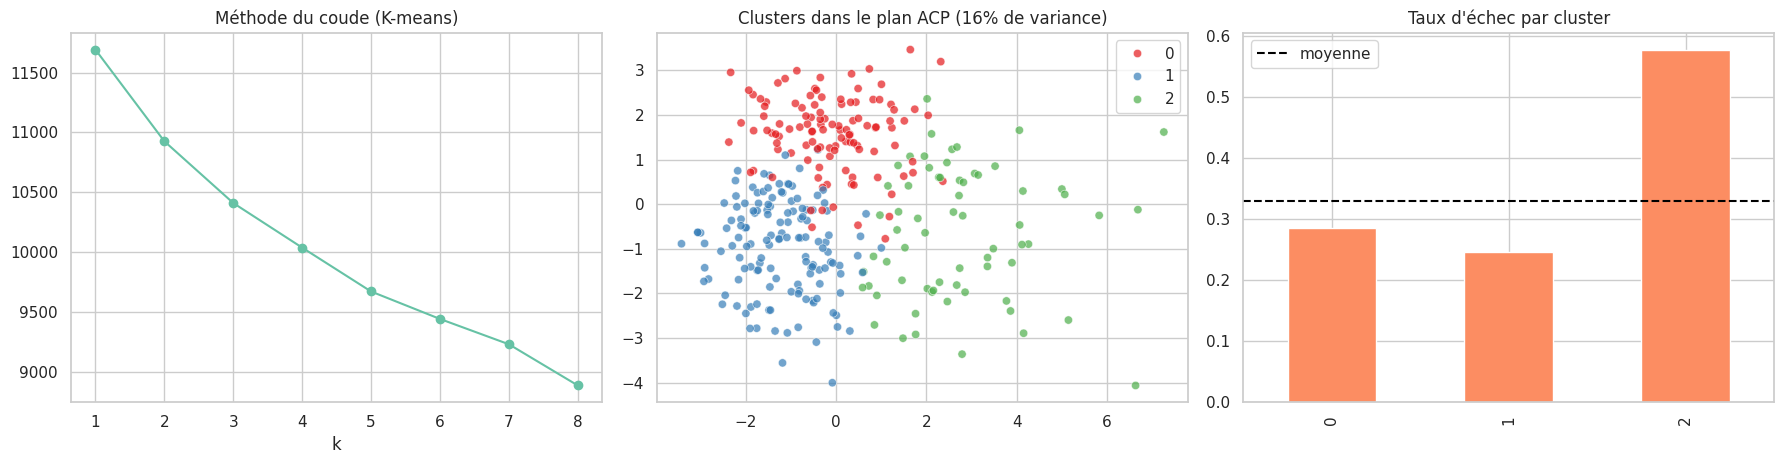

,age,failures,goout,alcool,studytime,parents_edu,higher,school
0,16.54,0.04,2.95,1.53,2.12,2.46,0.97,0.88
1,16.38,0.02,3.06,1.58,2.09,3.59,0.99,0.93
2,17.53,1.50,3.53,2.27,1.62,2.48,0.79,0.82


In [10]:
Z = StandardScaler().fit_transform(X_tr[profil])
pca = PCA(n_components=2, random_state=SEED).fit(Z); P = pca.transform(Z)
inerties = [KMeans(k, n_init=10, random_state=SEED).fit(Z).inertia_ for k in range(1, 9)]
km = KMeans(3, n_init=10, random_state=SEED).fit(Z)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].plot(range(1, 9), inerties, "o-"); ax[0].set_title("Méthode du coude (K-means)"); ax[0].set_xlabel("k")
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=km.labels_, palette="Set1", ax=ax[1], alpha=.7)
ax[1].set_title(f"Clusters dans le plan ACP ({pca.explained_variance_ratio_.sum():.0%} de variance)")
taux = pd.Series(y_tr.values).groupby(km.labels_).mean()
taux.plot.bar(ax=ax[2], color="#fc8d62"); ax[2].axhline(y_tr.mean(), color="k", ls="--", label="moyenne")
ax[2].set_title("Taux d'échec par cluster"); ax[2].legend()
plt.tight_layout(); plt.show()
X_tr[profil].groupby(km.labels_).mean()[["age", "failures", "goout", "alcool", "studytime", "parents_edu", "higher", "school"]].round(2)

**Interprétation.**
- Les deux premières composantes de l'ACP n'expliquent qu'environ **16 % de la variance** et la courbe du coude ne présente pas de cassure nette : **il n'y a pas de groupes naturellement bien séparés**, les élèves forment plutôt un continuum.
- Pourtant, un des clusters se démarque : des élèves **plus âgés, ayant déjà échoué, étudiant moins, sortant et buvant davantage**. Son taux d'échec avoisine **58 %**, contre 25 à 29 % pour les deux autres. Sans jamais avoir vu la cible, l'algorithme a isolé un profil à risque, ce qui confirme H1 et H4.
- Les deux autres clusters se distinguent surtout par l'éducation des parents, avec un écart de réussite modeste (H3).

À retenir pour la suite : le profil contient **un signal réel mais concentré sur quelques variables**, noyé dans beaucoup de variables peu informatives. On ne doit pas s'attendre à des performances spectaculaires dans le scénario A.

## 4. Phase d'apprentissage

### Choix des algorithmes
On compare des modèles de complexité croissante, chacun pour une raison précise :

| Modèle | Pourquoi |
|---|---|
| **Dummy** (classe majoritaire) | Référence minimale : tout modèle doit faire mieux |
| **Régression logistique** | Modèle linéaire simple, rapide, **interprétable** (coefficients). Bon choix de départ avec peu de données |
| **Arbre de décision** | Règles lisibles par un enseignant, capte les effets de seuil, mais **très sujet à l'overfitting** |
| **Random Forest** | Moyenne de nombreux arbres : réduit la variance de l'arbre seul, capte les interactions non linéaires |
| **Gradient Boosting** | Arbres construits séquentiellement pour corriger les erreurs des précédents : souvent le plus performant sur données tabulaires |

`class_weight="balanced"` donne plus de poids aux élèves en échec (minoritaires) pendant l'apprentissage, ce qui va dans le sens de notre objectif de rappel.

In [11]:
def pipe_lr(**kw):
    return Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", **kw))])

MODELES = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Régression logistique": pipe_lr(),
    "Arbre de décision": DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
    "Random Forest": RandomForestClassifier(300, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
}
SCORING = {"rappel": "recall", "précision": "precision", "F1": "f1", "AUC": "roc_auc"}

lignes = []
for scen, cols in SCENARIOS.items():
    for nom, m in MODELES.items():
        r = cross_validate(m, X_tr[cols], y_tr, cv=cv, scoring=SCORING, return_train_score=True)
        lignes.append({"Scénario": scen, "Modèle": nom,
                       **{k: r[f"test_{k}"].mean() for k in SCORING},
                       "F1 train": r["train_F1"].mean()})
res = pd.DataFrame(lignes)
res.round(3)

,Scénario,Modèle,rappel,précision,F1,AUC,F1 train
0,A (rentrée),Dummy,0.000,0.000,0.000,0.500,0.000
1,A (rentrée),Régression logistique,0.549,0.432,0.478,0.631,0.653
2,A (rentrée),Arbre de décision,0.326,0.301,0.313,0.479,0.996
3,A (rentrée),Random Forest,0.310,0.635,0.396,0.614,0.996
4,A (rentrée),Gradient Boosting,0.290,0.397,0.322,0.571,0.948
5,B (+G1),Dummy,0.000,0.000,0.000,0.500,0.000
6,B (+G1),Régression logistique,0.809,0.694,0.742,0.899,0.843
7,B (+G1),Arbre de décision,0.701,0.708,0.703,0.778,1.000
8,B (+G1),Random Forest,0.617,0.729,0.660,0.890,1.000
9,B (+G1),Gradient Boosting,0.694,0.650,0.668,0.891,0.996


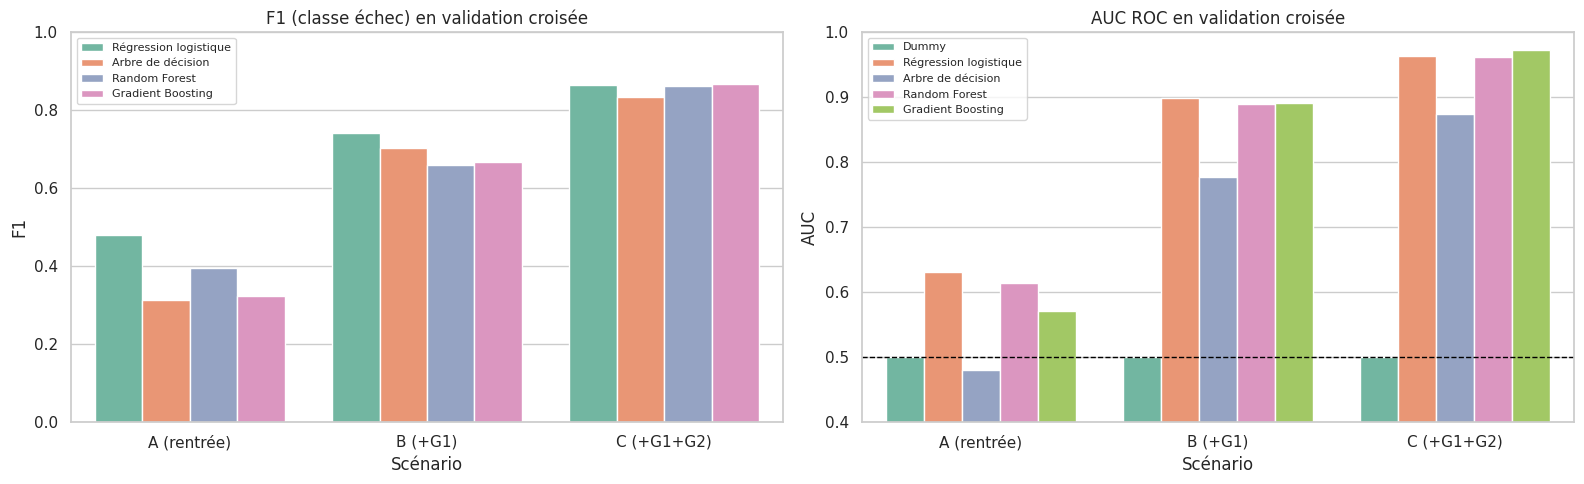

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=res[res.Modèle != "Dummy"], x="Scénario", y="F1", hue="Modèle", ax=ax[0])
ax[0].set_title("F1 (classe échec) en validation croisée"); ax[0].set_ylim(0, 1); ax[0].legend(fontsize=8)
sns.barplot(data=res, x="Scénario", y="AUC", hue="Modèle", ax=ax[1])
ax[1].axhline(.5, color="k", ls="--", lw=1); ax[1].set_title("AUC ROC en validation croisée"); ax[1].set_ylim(.4, 1)
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lecture des résultats**
- Le **Dummy** a un rappel et un F1 nuls : il ne détecte aucun élève en échec, malgré ses 67 % d'accuracy. Cela illustre pourquoi l'accuracy seule serait trompeuse ici.
- **Le moment de la prédiction change tout (H2)** : les performances bondissent du scénario A au scénario B, puis encore au C. Une seule note de premier trimestre vaut plus que les 37 variables de profil réunies.
- **Scénario A** : la régression logistique et la Random Forest font mieux que le hasard (AUC autour de 0,61 à 0,63), donc le profil contient du signal, mais les performances restent modestes, comme annoncé par l'exploration. L'arbre de décision non contraint fait même **moins bien que le hasard** (AUC ≈ 0,48).
- **Overfitting de l'arbre de décision** : comparer la colonne `F1 train` (proche de 1) au F1 en validation. L'arbre sans limite de profondeur **apprend par cœur** les élèves d'entraînement et généralise mal. C'est exactement ce que le réglage des hyperparamètres doit corriger.

Pour la suite, on se concentre sur le **scénario B (après le 1er trimestre)**, qui est le meilleur compromis pour le cas d'usage : on dispose d'un vrai signal, et il reste deux trimestres pour aider l'élève. Le scénario A reste présenté en comparaison.

## 5. Phase de réglage des hyperparamètres

Un **hyperparamètre** est un réglage du modèle **fixé avant l'apprentissage** (et non appris à partir des données, contrairement aux coefficients d'une régression ou aux seuils des arbres). Il contrôle la **complexité** du modèle, donc l'équilibre entre sous-apprentissage et **sur-apprentissage (overfitting)**.

### 5.1 Visualiser l'overfitting : la profondeur d'un arbre

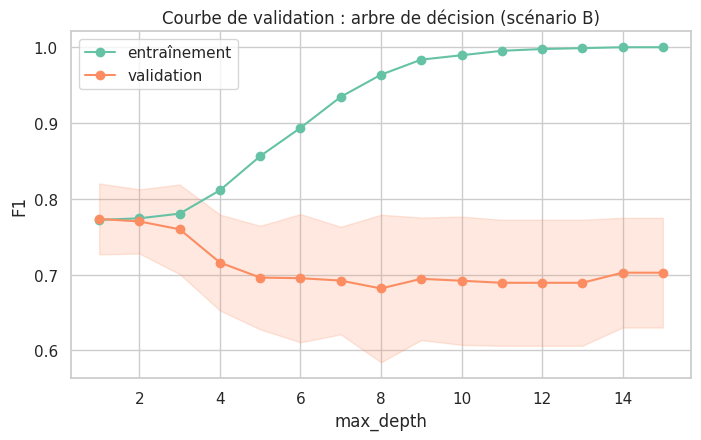

In [13]:
cols_B = SCENARIOS["B (+G1)"]
prof = np.arange(1, 16)
tr, va = validation_curve(DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
                          X_tr[cols_B], y_tr, param_name="max_depth", param_range=prof, cv=cv, scoring="f1")
plt.figure(figsize=(8, 4.5))
plt.plot(prof, tr.mean(1), "o-", label="entraînement"); plt.plot(prof, va.mean(1), "o-", label="validation")
plt.fill_between(prof, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=.2, color="C1")
plt.xlabel("max_depth"); plt.ylabel("F1"); plt.title("Courbe de validation : arbre de décision (scénario B)")
plt.legend(); plt.show()

Cette courbe illustre le compromis biais-variance :
- **À gauche** (arbre très peu profond) : le modèle est trop simple, il sous-apprend.
- **À droite** : le score d'entraînement monte vers 1 tandis que celui de validation baisse. Le modèle **mémorise le bruit** des élèves d'entraînement : c'est l'**overfitting**.
- Le bon réglage est là où le score de **validation** est maximal, avec une profondeur faible, ce qui donne en plus des règles lisibles.

### 5.2 Hyperparamètres importants et recherche par grille

| Modèle | Hyperparamètre | Rôle |
|---|---|---|
| Régression logistique | `C` | Inverse de la force de **régularisation** : petit C = modèle plus contraint, moins d'overfitting |
| Random Forest | `n_estimators` | Nombre d'arbres. Plus = plus stable, jamais d'overfitting, mais plus lent |
| | `max_depth` | Profondeur max de chaque arbre : **principal levier contre l'overfitting** |
| | `min_samples_leaf` | Nombre minimum d'élèves par feuille : empêche des règles basées sur 1 ou 2 élèves |
| | `max_features` | Nombre de variables tirées à chaque nœud : diversifie les arbres |
| Gradient Boosting | `learning_rate` × `n_estimators` | Vitesse d'apprentissage et nombre d'étapes : à régler **ensemble** (petit pas = plus d'étapes) |
| | `max_depth` | Souvent faible (2 à 4) : chaque arbre est un « apprenant faible » |
| | `subsample` | Fraction d'élèves utilisée par arbre : ajoute de l'aléa, régularise |

On utilise **GridSearchCV** : chaque combinaison est évaluée par validation croisée à 5 plis, et on garde celle qui maximise le **F1** de la classe échec. Le jeu de test n'est **jamais** utilisé à cette étape.

In [14]:
grilles = {
    "Régression logistique": (pipe_lr(), {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}),
    "Random Forest": (RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
                      {"n_estimators": [300], "max_depth": [3, 5, 8, None],
                       "min_samples_leaf": [1, 3, 5, 10], "max_features": ["sqrt", 0.5]}),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=SEED),
                          {"learning_rate": [0.03, 0.1], "n_estimators": [100, 300],
                           "max_depth": [2, 3], "subsample": [0.8, 1.0]}),
}
meilleurs, recap = {}, []
for scen in ["A (rentrée)", "B (+G1)"]:
    for nom, (m, g) in grilles.items():
        gs = GridSearchCV(m, g, cv=cv, scoring="f1", n_jobs=-1).fit(X_tr[SCENARIOS[scen]], y_tr)
        avant = res.query("Scénario == @scen and Modèle == @nom")["F1"].item()
        recap.append({"Scénario": scen, "Modèle": nom, "F1 défaut": avant,
                      "F1 réglé": gs.best_score_, "Meilleurs hyperparamètres": gs.best_params_})
        meilleurs[(scen, nom)] = gs.best_estimator_
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(recap).round(3)

,Scénario,Modèle,F1 défaut,F1 réglé,Meilleurs hyperparamètres
0,A (rentrée),Régression logistique,0.478,0.504,{'clf__C': 0.01}
1,A (rentrée),Random Forest,0.396,0.472,"{'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 300}"
2,A (rentrée),Gradient Boosting,0.322,0.452,"{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100, 'subsample': 1.0}"
3,B (+G1),Régression logistique,0.742,0.745,{'clf__C': 0.3}
4,B (+G1),Random Forest,0.660,0.773,"{'max_depth': 5, 'max_features': 0.5, 'min_samples_leaf': 10, 'n_estimators': 300}"
5,B (+G1),Gradient Boosting,0.668,0.732,"{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.8}"


**Discussion**
- Le réglage apporte un gain surtout pour les modèles à arbres, dont la configuration par défaut était trop complexe pour si peu de données. Les meilleurs réglages retiennent des arbres **peu profonds** et/ou des **feuilles d'au moins quelques élèves**, ce qui confirme que la lutte contre l'overfitting est l'enjeu principal.
- La **régression logistique** reste très compétitive. Sur un petit jeu de données tabulaire au signal faible, un modèle simple et bien régularisé rivalise souvent avec des modèles complexes : c'est un argument de plus contre le Deep Learning ici.
- Attention à ne pas sur-interpréter de petits écarts : avec environ 63 élèves par pli, l'écart-type du F1 entre plis est de plusieurs points.

### 5.3 Les écarts entre modèles sont-ils significatifs ?

Avec 316 élèves d'entraînement, le score obtenu dépend beaucoup de la façon dont on découpe les plis. Pour ne pas choisir un modèle « par chance », on répète la validation croisée **5 fois avec des découpages différents** (25 évaluations par modèle) et on regarde la **dispersion** des scores.

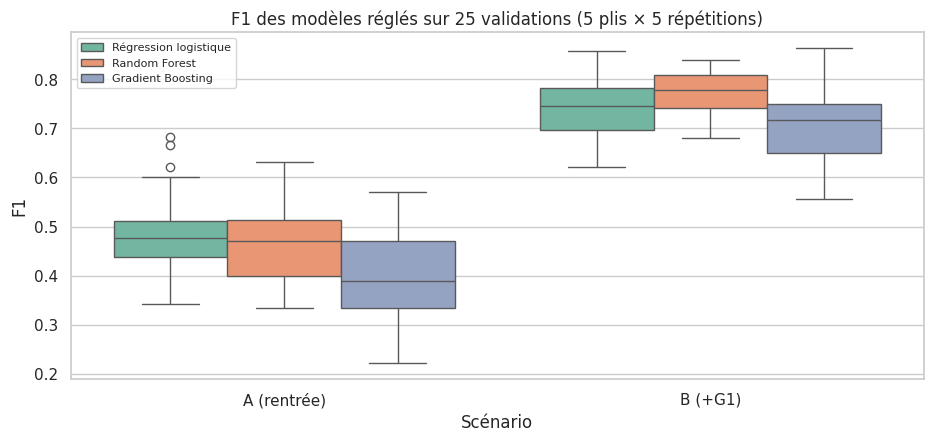

mean    std
Scénario    Modèle                             
A (rentrée) Gradient Boosting      0.397  0.103
            Random Forest          0.467  0.082
            Régression logistique  0.485  0.092
B (+G1)     Gradient Boosting      0.704  0.075
            Random Forest          0.770  0.044
            Régression logistique  0.734  0.069

In [15]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score, cross_val_predict
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
rob = []
for (scen, nom), m in meilleurs.items():
    sc = cross_val_score(m, X_tr[SCENARIOS[scen]], y_tr, cv=rcv, scoring="f1")
    rob += [{"Scénario": scen, "Modèle": nom, "F1": v} for v in sc]
rob = pd.DataFrame(rob)
plt.figure(figsize=(11, 4.5))
sns.boxplot(data=rob, x="Scénario", y="F1", hue="Modèle")
plt.title("F1 des modèles réglés sur 25 validations (5 plis × 5 répétitions)"); plt.legend(fontsize=8); plt.show()
rob.groupby(["Scénario", "Modèle"])["F1"].agg(["mean", "std"]).round(3)

**Lecture.** Les boîtes montrent que l'écart-type du F1 atteint 0,04 à 0,10 selon les modèles : **un écart de 2 ou 3 points entre deux modèles n'est pas significatif**.
- **Scénario A** : la régression logistique (0,49 ± 0,09) et la Random Forest (0,47 ± 0,08) sont **indiscernables**. Le Gradient Boosting est en retrait. À performances égales, on retient le modèle **le plus simple et le plus interprétable**, la régression logistique : c'est le principe du rasoir d'Ockham.
- **Scénario B** : la Random Forest (0,77 ± 0,04) devance légèrement les autres et surtout c'est la **plus stable** (plus petite dispersion). On la retient.

Ces choix sont cohérents avec ceux du GridSearch. On peut donc passer à l'évaluation finale avec confiance.

## 6. Évaluation finale sur le jeu de test

On sélectionne pour chaque scénario le modèle ayant le meilleur F1 en validation croisée, puis on l'évalue **une seule fois** sur les 79 élèves du jeu de test, jamais vus jusqu'ici.

=== Scénario A (rentrée) : Régression logistique ===
              precision    recall  f1-score   support

    Réussite      0.792     0.792     0.792        53
       Échec      0.577     0.577     0.577        26

    accuracy                          0.722        79
   macro avg      0.685     0.685     0.685        79
weighted avg      0.722     0.722     0.722        79

=== Scénario B (+G1) : Random Forest ===
              precision    recall  f1-score   support

    Réussite      0.976     0.774     0.863        53
       Échec      0.676     0.962     0.794        26

    accuracy                          0.835        79
   macro avg      0.826     0.868     0.828        79
weighted avg      0.877     0.835     0.840        79



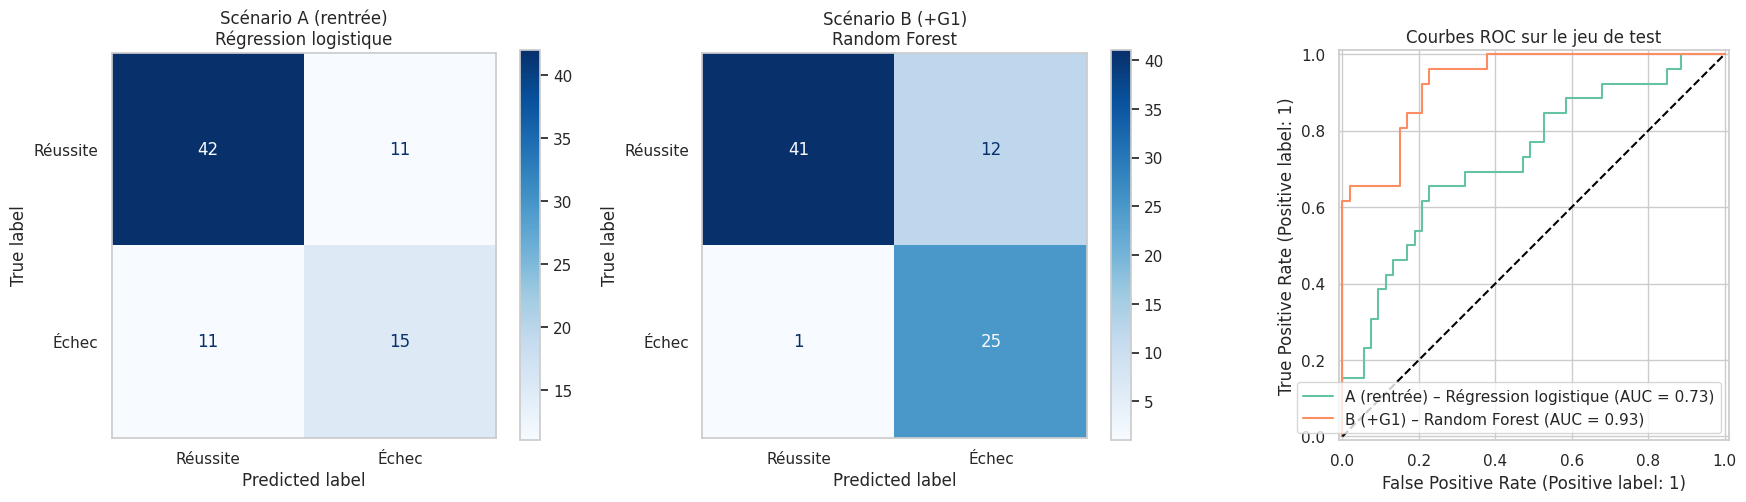

In [16]:
rec = pd.DataFrame(recap)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
finals = {}
for i, scen in enumerate(["A (rentrée)", "B (+G1)"]):
    nom = rec[rec.Scénario == scen].sort_values("F1 réglé").iloc[-1]["Modèle"]
    m = meilleurs[(scen, nom)]; cols = SCENARIOS[scen]; finals[scen] = (nom, m)
    pred = m.predict(X_te[cols])
    print(f"=== Scénario {scen} : {nom} ===")
    print(classification_report(y_te, pred, target_names=["Réussite", "Échec"], digits=3))
    ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["Réussite", "Échec"], cmap="Blues", ax=ax[i])
    ax[i].set_title(f"Scénario {scen}\n{nom}"); ax[i].grid(False)
    RocCurveDisplay.from_estimator(m, X_te[cols], y_te, ax=ax[2], name=f"{scen} – {nom}")
ax[2].plot([0, 1], [0, 1], "k--"); ax[2].set_title("Courbes ROC sur le jeu de test")
plt.tight_layout(); plt.show()

**Traduction pour l'établissement**
- La **matrice de confusion** se lit directement en nombre d'élèves : parmi les élèves du test qui ont réellement échoué, combien le modèle aurait-il repérés (vrais positifs) et combien seraient passés entre les mailles du filet (faux négatifs) ?
- **Scénario B (Random Forest réglée)** : après le premier trimestre, le modèle repère **25 des 26 élèves** qui vont échouer (rappel 0,96). En contrepartie, il signale 12 élèves qui auraient réussi (précision 0,68). Pour une école, c'est un compromis très acceptable : 37 élèves à suivre de près, parmi lesquels presque tous ceux qui en ont vraiment besoin, avec deux trimestres devant soi pour agir.
- **Scénario A (régression logistique)** : à la rentrée, le modèle détecte environ **6 échecs sur 10** (15 sur 26), avec 11 fausses alertes. Il peut servir de **premier filtre** (par exemple pour proposer un entretien individuel), pas de verdict.

### 6.1 Ajuster le seuil de décision selon le budget de l'école
Par défaut, un élève est signalé si sa probabilité d'échec dépasse 0,5. Mais l'école peut choisir ce seuil selon ses moyens : baisser le seuil augmente le rappel (moins d'élèves oubliés) au prix de plus de fausses alertes.

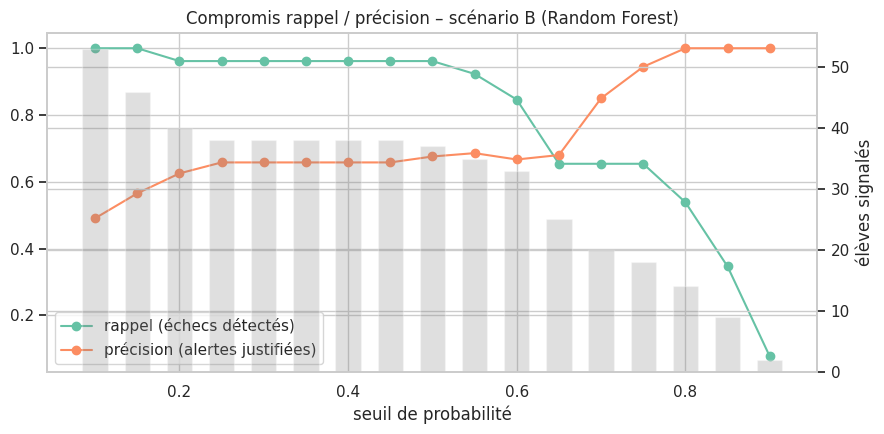

In [17]:
nom, m = finals["B (+G1)"]; cols = SCENARIOS["B (+G1)"]
proba = m.predict_proba(X_te[cols])[:, 1]
seuils = np.arange(0.1, 0.91, 0.05)
t = pd.DataFrame({"seuil": seuils,
                  "rappel": [recall_score(y_te, proba >= s) for s in seuils],
                  "précision": [precision_score(y_te, proba >= s, zero_division=0) for s in seuils],
                  "élèves signalés": [(proba >= s).sum() for s in seuils]})
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(t.seuil, t.rappel, "o-", label="rappel (échecs détectés)")
ax.plot(t.seuil, t.précision, "o-", label="précision (alertes justifiées)")
ax2 = ax.twinx(); ax2.bar(t.seuil, t["élèves signalés"], width=.03, alpha=.25, color="grey"); ax2.set_ylabel("élèves signalés")
ax.set_xlabel("seuil de probabilité"); ax.set_title(f"Compromis rappel / précision – scénario B ({nom})"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

Sur ce jeu de test, le rappel reste à 0,96 ou plus pour tout seuil entre 0,1 et 0,5 : le modèle sépare bien les élèves à risque. Au-delà de 0,6, le rappel chute nettement. Un lycée aux moyens très limités pourrait choisir un seuil de 0,75 (18 élèves signalés, plus de 9 alertes sur 10 justifiées) en acceptant d'en manquer un tiers. Le choix du seuil n'est pas une question technique : c'est une **décision de l'établissement**, selon le nombre d'élèves qu'il peut accompagner.

### 6.2 Quelles variables comptent ? (importance par permutation)

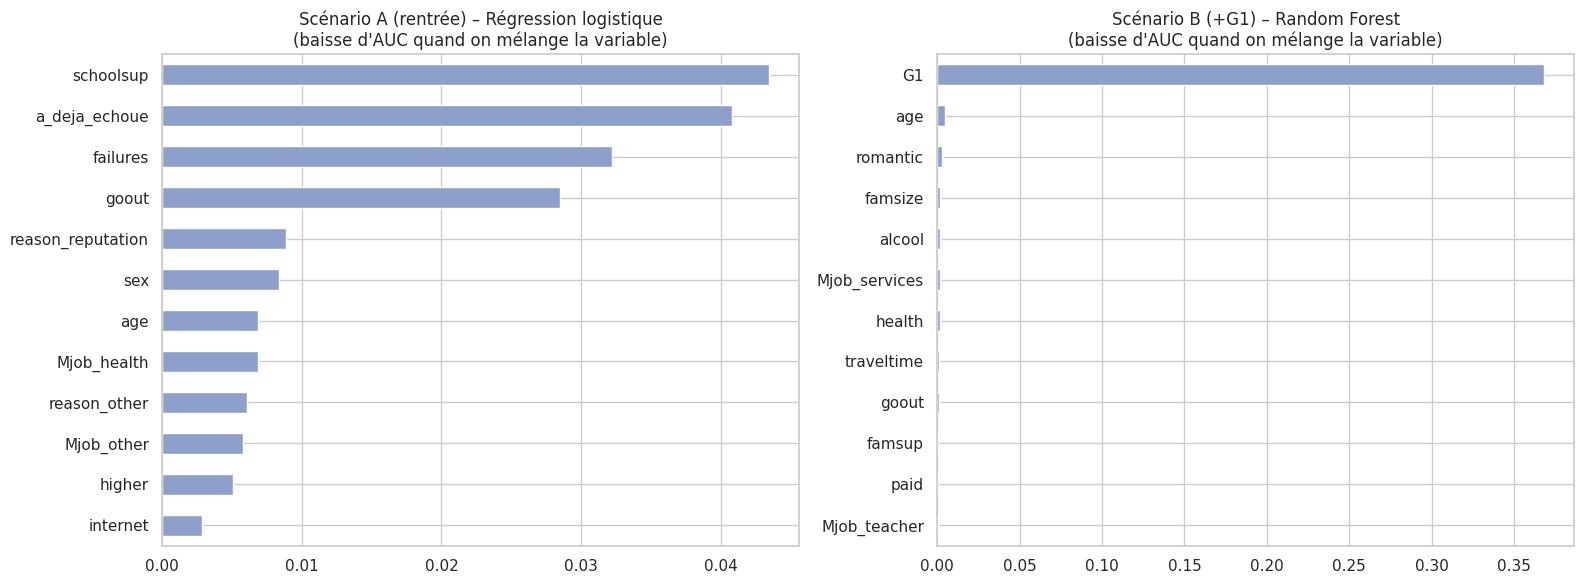

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, scen in zip(ax, ["A (rentrée)", "B (+G1)"]):
    nom, m = finals[scen]; cols = SCENARIOS[scen]
    pi = permutation_importance(m, X_te[cols], y_te, scoring="roc_auc", n_repeats=30, random_state=SEED)
    imp = pd.Series(pi.importances_mean, index=cols).sort_values().tail(12)
    imp.plot.barh(ax=a, color="#8da0cb"); a.set_title(f"Scénario {scen} – {nom}\n(baisse d'AUC quand on mélange la variable)")
plt.tight_layout(); plt.show()

L'**importance par permutation** mesure de combien la performance chute quand on mélange aléatoirement une variable : plus la chute est forte, plus le modèle s'appuie sur elle. Elle a l'avantage de s'appliquer à n'importe quel modèle.

**Retour sur les hypothèses**
- **H1 confirmée** : dans le scénario A, les échecs passés (`failures`, `a_deja_echoue`) sont parmi les variables les plus importantes.
- **H4 confirmée pour les sorties** : `goout` arrive juste après. L'alcool, en revanche, ne ressort pas.
- **H2 confirmée** : dans le scénario B, **G1 écrase tout le reste**, les autres variables ont une importance quasi nulle. Le modèle se comporte presque comme une règle sur la note du premier trimestre, affinée par le profil.
- **H3 et H5** : le contexte familial et l'ambition d'études supérieures n'apportent qu'une contribution faible ici. Avec 395 élèves, on ne peut pas conclure fermement.
- **Un piège instructif : `schoolsup`** (soutien scolaire de l'établissement) est la variable la plus importante du scénario A. Faut-il en conclure que le soutien fait échouer ? Évidemment non : ce sont **les élèves déjà en difficulté qui reçoivent ce soutien**. C'est une **causalité inversée**, exemple typique de la différence entre **corrélation et causalité**. Les importances décrivent ce que le modèle utilise, **jamais des causes**.

## 7. Analyses complémentaires

Les sections précédentes répondent au problème principal. Cette partie teste la **solidité** des conclusions et explore d'autres angles du cas d'usage.

In [19]:
from sklearn.base import clone
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.tree import plot_tree

def cv_score(m, X, yy, sc="f1"):
    r = cross_val_score(m, X, yy, cv=rcv, scoring=sc)
    return r.mean(), r.std()

modele_A = finals["A (rentrée)"][1]
modele_B = finals["B (+G1)"][1]

### 7.1 Et si l'on prédisait la note exacte ? (régression)

Au lieu de « échec ou réussite », on prédit directement **G3 sur 20**. La métrique devient l'**erreur absolue moyenne (MAE)** : de combien de points le modèle se trompe en moyenne.

La vraie question est de savoir si le ML fait mieux qu'une **règle naïve** qu'un enseignant appliquerait sans ordinateur : prédire la moyenne de la classe, ou recopier la dernière note connue (G3 = G1, G3 = G2).

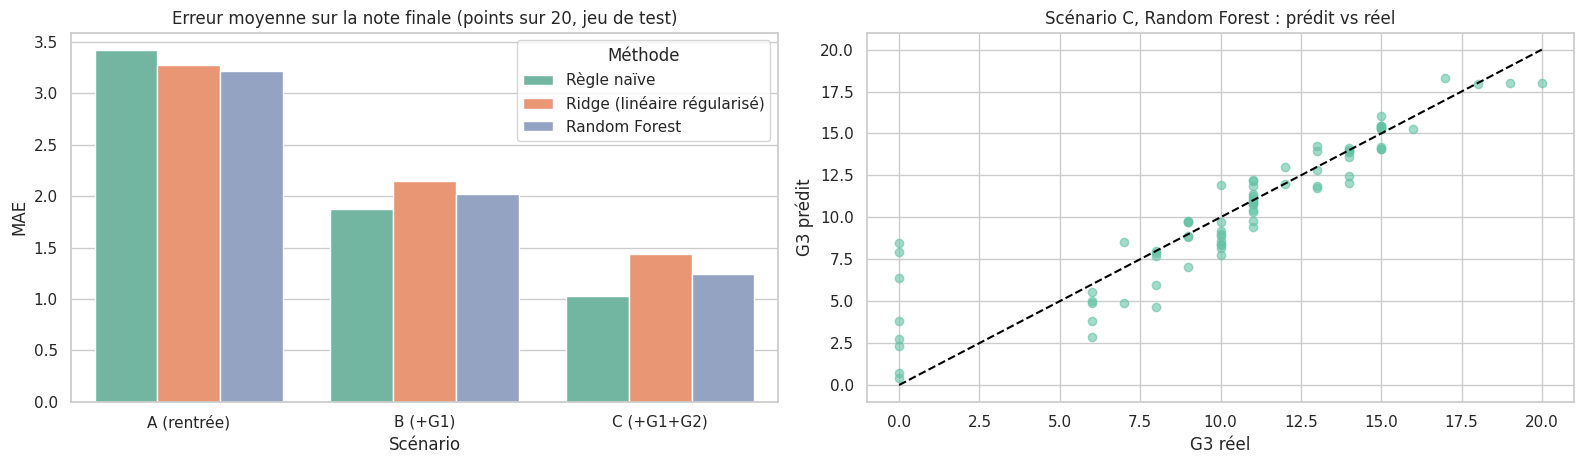

Scénario,A (rentrée),B (+G1),C (+G1+G2)
Méthode,,,
Random Forest,3.22,2.02,1.24
Ridge (linéaire régularisé),3.28,2.14,1.43
Règle naïve,3.42,1.87,1.03


In [20]:
G3_tr, G3_te = df.loc[X_tr.index, "G3"], df.loc[X_te.index, "G3"]
reg = []
naifs = {"A (rentrée)": ("Moyenne de la classe", np.full(len(G3_te), G3_tr.mean())),
         "B (+G1)": ("Recopier G1", X_te["G1"]), "C (+G1+G2)": ("Recopier G2", X_te["G2"])}
for scen, cols in SCENARIOS.items():
    nom_naif, pred_naif = naifs[scen]
    reg.append({"Scénario": scen, "Méthode": "Règle naïve", "MAE": mean_absolute_error(G3_te, pred_naif), "détail": nom_naif})
    for nom, m in [("Ridge (linéaire régularisé)", Pipeline([("sc", StandardScaler()), ("r", RidgeCV(alphas=np.logspace(-2, 3, 30)))])),
                   ("Random Forest", RandomForestRegressor(300, min_samples_leaf=3, random_state=SEED, n_jobs=-1))]:
        m.fit(X_tr[cols], G3_tr); reg.append({"Scénario": scen, "Méthode": nom, "MAE": mean_absolute_error(G3_te, m.predict(X_te[cols])), "détail": ""})
    if scen == "C (+G1+G2)": rf_reg_C = m
reg = pd.DataFrame(reg)

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
sns.barplot(data=reg, x="Scénario", y="MAE", hue="Méthode", ax=ax[0])
ax[0].set_title("Erreur moyenne sur la note finale (points sur 20, jeu de test)")
p = rf_reg_C.predict(X_te[SCENARIOS["C (+G1+G2)"]])
ax[1].scatter(G3_te, p, alpha=.6); ax[1].plot([0, 20], [0, 20], "k--")
ax[1].set_xlabel("G3 réel"); ax[1].set_ylabel("G3 prédit"); ax[1].set_title("Scénario C, Random Forest : prédit vs réel")
plt.tight_layout(); plt.show()
reg.pivot(index="Méthode", columns="Scénario", values="MAE").round(2)

**Résultat surprenant, et instructif.**
- **Scénario A** : les modèles font à peine mieux que la moyenne de la classe (3,2 contre 3,4 points d'erreur). Le profil seul ne permet pas de deviner la note.
- **Scénarios B et C** : **la règle naïve gagne**. Recopier G1 se trompe en moyenne de 1,9 point, contre 2,0 pour le meilleur modèle. Recopier G2 se trompe de 1,0 point, contre 1,2.

Pourquoi ? Les notes d'un élève sont très **stables** d'un trimestre à l'autre, et les autres variables ajoutent surtout du bruit que le modèle apprend en partie (overfitting). De plus, l'erreur moyenne est tirée vers le haut par les abandons (G3 = 0), que personne ne sait prédire à partir des notes.

**Leçon méthodologique** : il faut **toujours comparer un modèle de ML à une règle simple**. Sans cette comparaison, une MAE de 1,2 point aurait paru excellente. Ce résultat conforte aussi notre choix initial de la classification : prédire la note exacte n'est pas ce dont l'établissement a besoin, et c'est là que le ML apporte le moins.

### 7.2 Les notes nulles : abandons et fuite de données

L'exploration (section 2.2) a montré que les 38 élèves à G3 = 0 ont **tous** 0 absence. Cela pose deux questions :
1. Peut-on détecter à l'avance ces **abandons**, qui sont un problème différent de l'échec ?
2. La variable `absences` est-elle vraiment utilisable ? Si le nombre d'absences n'est complet qu'en fin d'année, et que les abandons n'ont plus été comptés, alors cette variable **contient la réponse** : c'est une **fuite de données** (*data leakage*), qui fait paraître un modèle bien meilleur qu'il ne le sera en conditions réelles.

Abandons dans le jeu d'entraînement : 30 (9%)
Part d'élèves à 0 absence : 100% chez les G3 = 0, 22% chez les autres


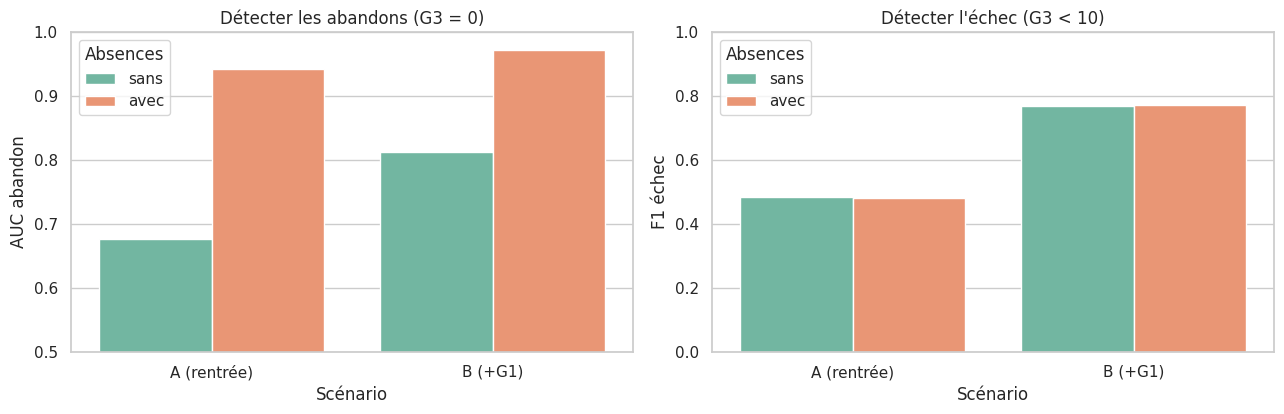

,Scénario,Absences,AUC abandon,± abandon,F1 échec,± échec
0,A (rentrée),sans,0.677,0.094,0.485,0.090
1,A (rentrée),avec,0.943,0.025,0.481,0.092
2,B (+G1),sans,0.812,0.055,0.770,0.043
3,B (+G1),avec,0.973,0.019,0.773,0.042


In [21]:
abandon = (df.loc[X_tr.index, "G3"] == 0).astype(int)
print(f"Abandons dans le jeu d'entraînement : {abandon.sum()} ({abandon.mean():.0%})")
print(f"Part d'élèves à 0 absence : {(df.absences[df.G3 == 0] == 0).mean():.0%} chez les G3 = 0, "
      f"{(df.absences[df.G3 > 0] == 0).mean():.0%} chez les autres")

rf_ab = RandomForestClassifier(300, min_samples_leaf=3, class_weight="balanced", random_state=SEED, n_jobs=-1)
fuite = []
for scen in ["A (rentrée)", "B (+G1)"]:
    cols = SCENARIOS[scen]
    for avec in [False, True]:
        c = cols + (["log_absences"] if avec else [])
        auc_ab, sd_ab = cv_score(rf_ab, X_tr[c], abandon, "roc_auc")
        f1_ec, sd_ec = cv_score(modele_A if scen.startswith("A") else modele_B, X_tr[c], y_tr, "f1")
        fuite.append({"Scénario": scen, "Absences": "avec" if avec else "sans",
                      "AUC abandon": auc_ab, "± abandon": sd_ab, "F1 échec": f1_ec, "± échec": sd_ec})
fuite = pd.DataFrame(fuite)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
sns.barplot(data=fuite, x="Scénario", y="AUC abandon", hue="Absences", ax=ax[0]); ax[0].set_ylim(.5, 1)
ax[0].set_title("Détecter les abandons (G3 = 0)")
sns.barplot(data=fuite, x="Scénario", y="F1 échec", hue="Absences", ax=ax[1]); ax[1].set_ylim(0, 1)
ax[1].set_title("Détecter l'échec (G3 < 10)")
plt.tight_layout(); plt.show()
fuite.round(3)

**Une fuite de données démasquée.**
- **Avec** la variable `absences`, on détecterait les abandons dès la rentrée avec une AUC de 0,94, un résultat spectaculaire. **Sans** elle, l'AUC tombe à 0,68. Tout le « talent » du modèle venait de la règle « 0 absence = abandon », qui n'existe **qu'a posteriori** : un élève qui a quitté l'école n'accumule plus d'absences. En conditions réelles, à la rentrée, cette information n'existe pas.
- Pour la détection de **l'échec**, retirer les absences **ne coûte rien** (F1 identique à ± 0,01 près). Notre choix de feature engineering (section 3) est donc validé : on se prive d'une fausse bonne variable sans perte réelle.
- Après le 1er trimestre, les abandons deviennent assez bien prévisibles (AUC ≈ 0,81), car une note G1 très faible en est un signe avant-coureur.

**À retenir** : pour chaque feature, il faut se demander **« cette information sera-t-elle disponible au moment où l'on fera la prédiction ? »**. C'est typiquement une question à poser aux personnes qui ont collecté les données : comment et quand les absences sont-elles enregistrées ?

### 7.3 Que nous apprend le cours de portugais ?

Le jeu de données contient aussi 649 élèves suivant le cours de portugais, dont une partie suit aussi les maths. Le script R fourni les apparie sur 13 attributs identiques (école, sexe, âge, profession des parents…). Trois questions :
1. L'appariement est-il fiable ?
2. Les facteurs de réussite sont-ils les mêmes dans les deux matières ?
3. La note de portugais aide-t-elle à prédire l'échec en maths ?

In [22]:
por = pd.read_csv("data/student-por.csv", sep=";")
mat = pd.read_csv("data/student-mat.csv", sep=";")
cles = ["school", "sex", "age", "address", "famsize", "Pstatus", "Medu", "Fedu", "Mjob", "Fjob", "reason", "nursery", "internet"]
print("Fusion brute (comme le script R) :", len(mat.merge(por, on=cles)), "lignes")
print("Profils en double dans maths :", mat.duplicated(cles, keep=False).sum(), "| dans portugais :", por.duplicated(cles, keep=False).sum())

# on ne garde que les élèves dont le profil est unique dans chaque fichier : appariement sans ambiguïté
m1 = mat[~mat.duplicated(cles, keep=False)].reset_index()
p1 = por[~por.duplicated(cles, keep=False)]
fus = m1.merge(p1[cles + ["G1", "G3", "failures", "paid", "studytime", "famsup"]], on=cles, suffixes=("", "_por"))
print("Fusion propre :", len(fus), "élèves")
for c in ["studytime", "famsup", "failures", "paid"]:
    print(f"  {c:10s} différent entre les deux fichiers pour {(fus[c] != fus[c + '_por']).mean():.0%} des élèves")
print(f"Corrélation note finale maths / portugais : r = {fus.G3.corr(fus.G3_por):.2f}")

Fusion brute (comme le script R) : 382 lignes
Profils en double dans maths : 8 | dans portugais : 23
Fusion propre : 358 élèves
  studytime  différent entre les deux fichiers pour 0% des élèves
  famsup     différent entre les deux fichiers pour 0% des élèves
  failures   différent entre les deux fichiers pour 13% des élèves
  paid       différent entre les deux fichiers pour 46% des élèves
Corrélation note finale maths / portugais : r = 0.48


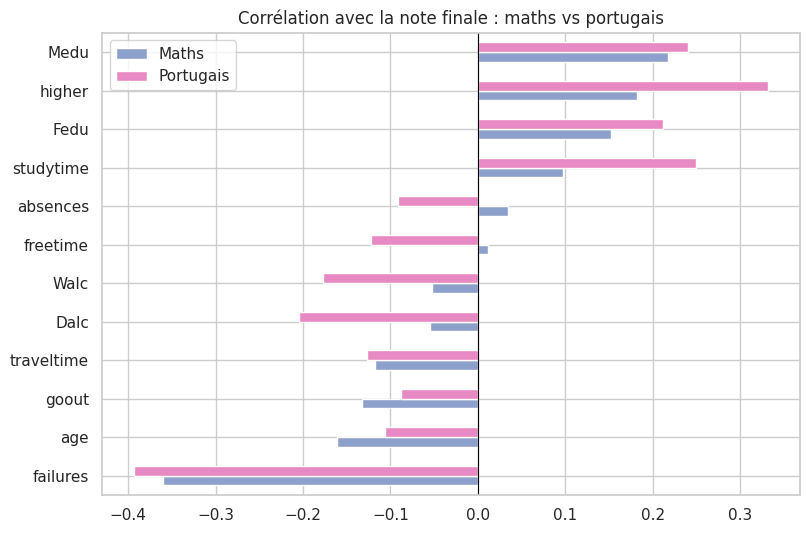

In [23]:
facteurs = ["failures", "Medu", "Fedu", "studytime", "higher", "goout", "Dalc", "Walc", "freetime", "age", "traveltime", "absences"]
def corr_g3(d):
    d = d.assign(higher=(d.higher == "yes").astype(int))
    return d[facteurs].corrwith(d.G3)
comp = pd.DataFrame({"Maths": corr_g3(mat), "Portugais": corr_g3(por)}).sort_values("Maths")
comp.plot.barh(figsize=(9, 6), color=["#8da0cb", "#e78ac3"])
plt.axvline(0, color="k", lw=.8); plt.title("Corrélation avec la note finale : maths vs portugais"); plt.show()

In [24]:
Xf = X_all.loc[fus["index"]].reset_index(drop=True); yf = y.loc[fus["index"]].reset_index(drop=True)
Xf["G1_por"] = fus["G1_por"].values
enrich = []
for nom, cols, m in [("A : profil seul", profil, modele_A),
                     ("A' : profil + G1 portugais", profil + ["G1_por"], modele_A),
                     ("B : profil + G1 maths", profil + ["G1"], modele_B),
                     ("B' : profil + G1 maths + G1 portugais", profil + ["G1", "G1_por"], modele_B)]:
    f1m, f1s = cv_score(m, Xf[cols], yf, "f1"); aucm, aucs = cv_score(m, Xf[cols], yf, "roc_auc")
    enrich.append({"Variables": nom, "F1": f1m, "± F1": f1s, "AUC": aucm, "± AUC": aucs})
pd.DataFrame(enrich).round(3)

,Variables,F1,± F1,AUC,± AUC
0,A : profil seul,0.530,0.096,0.717,0.076
1,A' : profil + G1 portugais,0.569,0.098,0.778,0.061
2,B : profil + G1 maths,0.743,0.060,0.910,0.032
3,B' : profil + G1 maths + G1 portugais,0.743,0.058,0.910,0.034


**1. L'appariement du script R n'est pas parfait.** Il donne 382 lignes, mais 8 profils du fichier de maths et 23 du fichier de portugais sont **en double** : plusieurs élèves partagent exactement les mêmes 13 attributs. Pour eux, le script associe un élève de maths à plusieurs élèves de portugais, dont certains ne sont pas la même personne. En ne gardant que les profils uniques, on obtient **358 élèves appariés sans ambiguïté**. On vérifie la qualité de l'appariement sur des variables qui ne servent pas de clé : `studytime` et `famsup` sont identiques dans 100 % des cas, ce qui confirme qu'il s'agit bien des mêmes élèves. `failures` et `paid` diffèrent, ce qui est logique : ils concernent **la matière** (échecs passés et cours payants en maths ou en portugais).

**2. Les facteurs de réussite diffèrent selon la matière.** Les échecs passés et l'éducation de la mère comptent autant dans les deux. En revanche, le **temps d'étude** et l'**alcool** sont bien plus liés à la note en portugais qu'en maths. Un modèle entraîné sur une matière ne doit donc pas être appliqué tel quel à l'autre.

**3. La note de portugais aide, mais seulement en l'absence de la note de maths.** Les notes finales des deux matières sont modérément corrélées (r = 0,48) : il existe un « niveau scolaire général ». Ajouter la note de portugais du 1er trimestre au profil améliore le F1 (0,53 → 0,57) et l'AUC (0,72 → 0,78). Mais dès que la note de maths G1 est connue, la note de portugais **n'apporte plus rien** (0,743 dans les deux cas) : l'information est redondante.

Conséquence pratique : ce qui manque vraiment au scénario A, ce sont **les notes de l'année précédente**, qui seraient disponibles dès la rentrée. C'est une donnée à demander en priorité à l'établissement.

*Note : les scores de ce tableau sont calculés sur les 358 élèves appariés, ils ne sont donc comparables qu'entre eux.*

### 7.4 Le modèle est-il équitable ?

Un outil d'aide à la décision utilisé sur des élèves doit être vérifié sous l'angle de l'**équité** : le modèle oublie-t-il plus souvent les élèves en difficulté d'un groupe que d'un autre ? On mesure le **rappel par groupe** (sexe, milieu urbain ou rural, lycée) à partir de prédictions en validation croisée sur le jeu d'entraînement, pour disposer d'assez d'élèves par groupe.

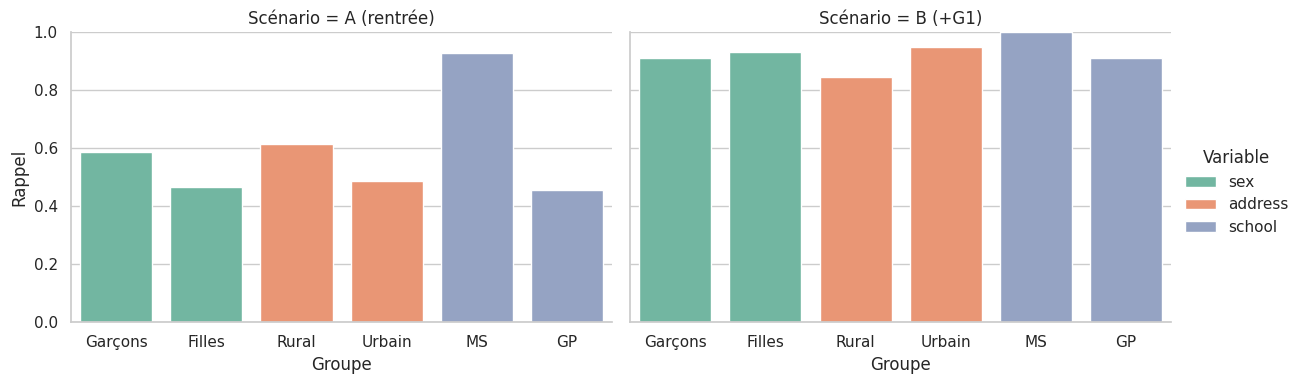

,Scénario,Variable,Groupe,Élèves,Échecs,Rappel,Précision
0,A (rentrée),sex,Garçons,151,46,0.59,0.56
1,A (rentrée),sex,Filles,165,58,0.47,0.44
2,A (rentrée),address,Rural,68,26,0.62,0.55
3,A (rentrée),address,Urbain,248,78,0.49,0.48
4,A (rentrée),school,MS,36,14,0.93,0.65
5,A (rentrée),school,GP,280,90,0.46,0.46
6,B (+G1),sex,Garçons,151,46,0.91,0.70
7,B (+G1),sex,Filles,165,58,0.93,0.64
8,B (+G1),address,Rural,68,26,0.85,0.61
9,B (+G1),address,Urbain,248,78,0.95,0.68


In [25]:
groupes = {"sex": {0: "Garçons", 1: "Filles"}, "address": {0: "Rural", 1: "Urbain"}, "school": {0: "MS", 1: "GP"}}
eq = []
for scen, m in [("A (rentrée)", modele_A), ("B (+G1)", modele_B)]:
    pred = cross_val_predict(m, X_tr[SCENARIOS[scen]], y_tr, cv=cv)
    for g, lab in groupes.items():
        for v, nom in lab.items():
            mk = (X_tr[g] == v).values
            eq.append({"Scénario": scen, "Variable": g, "Groupe": nom, "Élèves": mk.sum(), "Échecs": y_tr[mk].sum(),
                       "Rappel": recall_score(y_tr[mk], pred[mk]), "Précision": precision_score(y_tr[mk], pred[mk], zero_division=0)})
eq = pd.DataFrame(eq)
g = sns.catplot(data=eq, x="Groupe", y="Rappel", col="Scénario", hue="Variable", kind="bar", dodge=False, height=4, aspect=1.5)
g.set(ylim=(0, 1)); plt.show()
eq.round(2)

In [26]:
sensibles = ["sex", "address"] + [c for c in profil if c.startswith(("Mjob", "Fjob"))]
profil_neutre = [c for c in profil if c not in sensibles]
res_eq = []
for scen, m, extra in [("A (rentrée)", modele_A, []), ("B (+G1)", modele_B, ["G1"])]:
    for nom, cols in [("toutes les variables", profil + extra), ("sans variables sensibles", profil_neutre + extra)]:
        f, sd = cv_score(m, X_tr[cols], y_tr)
        res_eq.append({"Scénario": scen, "Variables": nom, "F1": f, "±": sd})
print("Variables retirées :", sensibles)
pd.DataFrame(res_eq).round(3)

Variables retirées : ['sex', 'address', 'Mjob_health', 'Mjob_other', 'Mjob_services', 'Mjob_teacher', 'Fjob_health', 'Fjob_other', 'Fjob_services', 'Fjob_teacher']


,Scénario,Variables,F1,±
0,A (rentrée),toutes les variables,0.485,0.090
1,A (rentrée),sans variables sensibles,0.499,0.067
2,B (+G1),toutes les variables,0.770,0.043
3,B (+G1),sans variables sensibles,0.766,0.043


**Lecture.**
- **À la rentrée (scénario A), le modèle n'est pas équitable.** Il repère 59 % des garçons en difficulté contre 47 % des filles, et 62 % des élèves ruraux contre 49 % des urbains. Une hypothèse : le modèle s'appuie sur des signaux visibles (redoublements, sorties fréquentes) qui accompagnent moins souvent l'échec chez les filles et les élèves urbains. Leurs difficultés passent donc plus souvent inaperçues. L'écart pour le lycée MS (93 %) repose sur seulement 14 élèves en échec et n'est pas interprétable.
- **Après le 1er trimestre (scénario B), les écarts se réduisent fortement** (91 % contre 93 % selon le sexe, 85 % contre 95 % selon le milieu), car la note G1 est un signal objectif, le même pour tous.
- **Retirer les variables sensibles** (sexe, milieu, métier des parents) **ne coûte rien** en performance (0,50 contre 0,49 dans le scénario A, 0,77 dans les deux cas pour B). On recommande donc de les exclure d'un outil déployé : on évite qu'une alerte repose sur « l'élève est un garçon » ou « son père est au foyer ».

**Limite** : retirer une variable ne suffit pas à garantir l'équité, car d'autres variables peuvent jouer le même rôle indirectement (l'éducation des parents, par exemple, est liée au métier). Il faut **mesurer** l'équité, comme ici, et pas seulement la supposer.

### 7.5 Le modèle fonctionnerait-il dans un autre lycée ?

Si le rectorat voulait déployer l'outil ailleurs, le modèle devrait **généraliser à un établissement qu'il n'a jamais vu**. On le simule en entraînant uniquement sur Gabriel Pereira (GP) et en testant sur Mousinho da Silveira (MS).

In [27]:
gp, ms = X_all["school"] == 1, X_all["school"] == 0
print(f"GP : {gp.sum()} élèves ({y[gp].mean():.0%} d'échecs) | MS : {ms.sum()} élèves ({y[ms].mean():.0%} d'échecs)")
tr_ = []
for scen, m in [("A (rentrée)", modele_A), ("B (+G1)", modele_B)]:
    cols = [c for c in SCENARIOS[scen] if c != "school"]
    mm = clone(m).fit(X_all.loc[gp, cols], y[gp]); p = mm.predict(X_all.loc[ms, cols])
    tr_.append({"Scénario": scen, "Rappel MS": recall_score(y[ms], p), "Précision MS": precision_score(y[ms], p),
                "F1 MS": f1_score(y[ms], p), "Échecs détectés": f"{p[y[ms].values == 1].sum()} / {y[ms].sum()}"})
pd.DataFrame(tr_).round(2)

GP : 349 élèves (32% d'échecs) | MS : 46 élèves (37% d'échecs)


,Scénario,Rappel MS,Précision MS,F1 MS,Échecs détectés
0,A (rentrée),0.88,0.60,0.71,15 / 17
1,B (+G1),1.00,0.74,0.85,17 / 17


**Lecture.** Entraîné uniquement sur GP, le modèle repère **15 des 17** élèves en échec de MS à la rentrée, et **les 17** après le 1er trimestre. C'est encourageant : les facteurs d'échec semblent proches d'un lycée à l'autre.

Mais il faut rester prudent : MS ne compte que **46 élèves et 17 échecs**, donc chaque élève pèse 6 points de rappel. De plus, les deux lycées sont dans la même région et le même système scolaire. Avant un déploiement ailleurs, il faudrait une **phase pilote** dans le nouvel établissement, où l'on compare les alertes du modèle au jugement des enseignants.

### 7.6 Faut-il vraiment 37 variables ? (parcimonie et lisibilité)

Chaque variable du profil correspond à une question posée à l'élève ou à sa famille. Un modèle qui obtient les mêmes performances avec **moins de variables** est plus simple à déployer (questionnaire plus court), plus facile à expliquer, et moins exposé à l'overfitting. On sélectionne les *k* variables les plus liées à l'échec (test statistique ANOVA F), **à l'intérieur de la validation croisée** pour ne pas tricher.

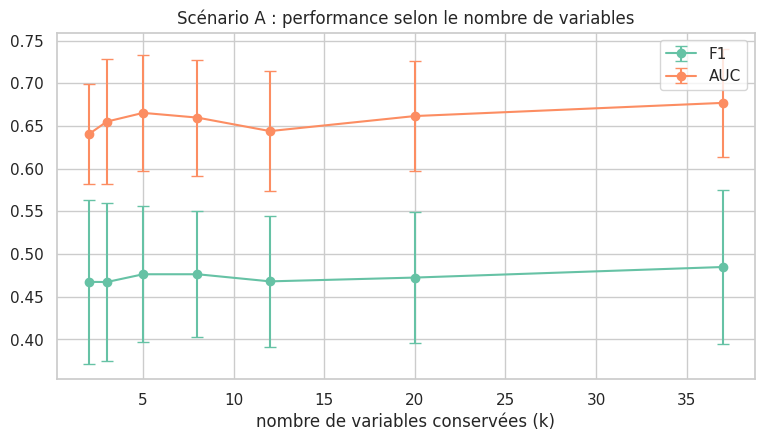

Les 5 variables retenues : [np.str_('age'), np.str_('failures'), np.str_('higher'), np.str_('goout'), np.str_('a_deja_echoue')]


In [28]:
C_A = modele_A.get_params().get("clf__C", 1.0) if hasattr(modele_A, "named_steps") else 0.1
ks, par = [2, 3, 5, 8, 12, 20, len(profil)], []
for k in ks:
    p = Pipeline([("sc", StandardScaler()), ("k", SelectKBest(f_classif, k=k)),
                  ("clf", LogisticRegression(C=C_A, class_weight="balanced", max_iter=2000))])
    f, fs = cv_score(p, X_tr[profil], y_tr); a, as_ = cv_score(p, X_tr[profil], y_tr, "roc_auc")
    par.append({"k": k, "F1": f, "F1_sd": fs, "AUC": a, "AUC_sd": as_})
par = pd.DataFrame(par)
plt.figure(figsize=(9, 4.5))
for met in ["F1", "AUC"]:
    plt.errorbar(par.k, par[met], yerr=par[met + "_sd"], marker="o", capsize=4, label=met)
plt.xlabel("nombre de variables conservées (k)"); plt.title("Scénario A : performance selon le nombre de variables"); plt.legend(); plt.show()
sel = SelectKBest(f_classif, k=5).fit(X_tr[profil], y_tr)
print("Les 5 variables retenues :", list(np.array(profil)[sel.get_support()]))

Pour le scénario B, on peut aller jusqu'au bout de la logique de lisibilité : un **arbre de décision de profondeur 3**, que l'on peut imprimer et donner aux enseignants.

F1 arbre de profondeur 3 : 0.759 ± 0.043  |  meilleur modèle du scénario B : 0.770 ± 0.043


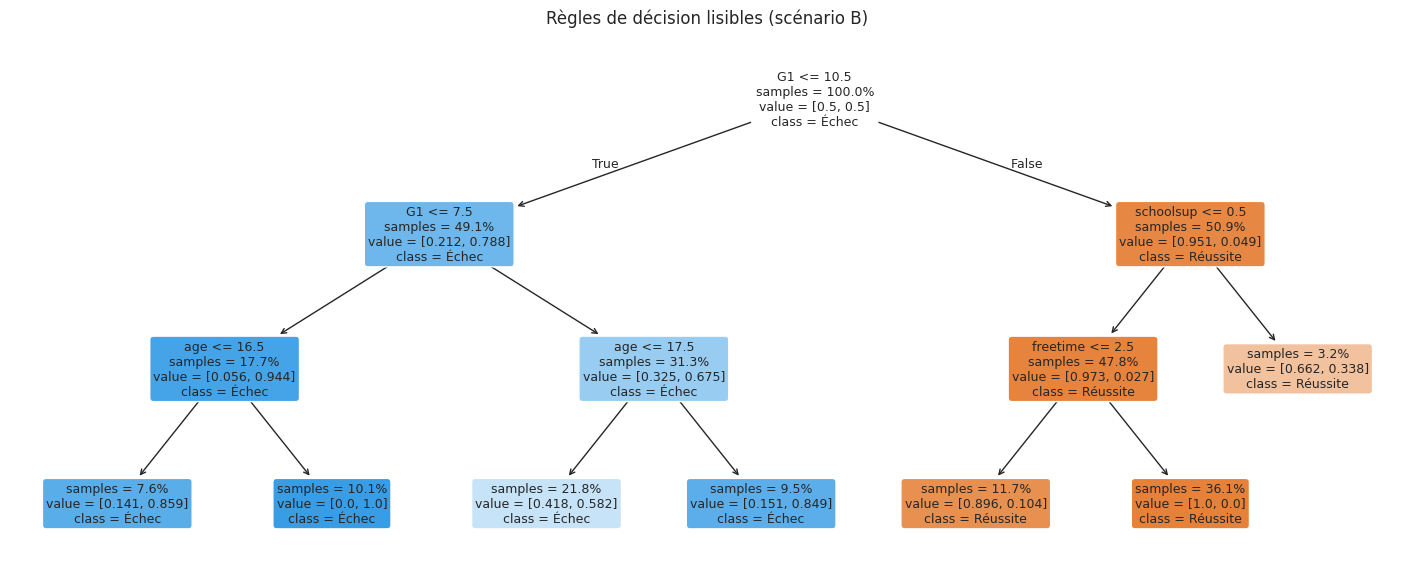

In [29]:
arbre = DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, class_weight="balanced", random_state=SEED)
f, fs = cv_score(arbre, X_tr[SCENARIOS["B (+G1)"]], y_tr)
fm, fms = cv_score(modele_B, X_tr[SCENARIOS["B (+G1)"]], y_tr)
print(f"F1 arbre de profondeur 3 : {f:.3f} ± {fs:.3f}  |  meilleur modèle du scénario B : {fm:.3f} ± {fms:.3f}")
arbre.fit(X_tr[SCENARIOS["B (+G1)"]], y_tr)
plt.figure(figsize=(18, 7))
plot_tree(arbre, feature_names=SCENARIOS["B (+G1)"], class_names=["Réussite", "Échec"], filled=True, rounded=True, fontsize=9, impurity=False, proportion=True)
plt.title("Règles de décision lisibles (scénario B)"); plt.show()

**Deux résultats forts.**

**1. Cinq questions suffisent à la rentrée.** Avec les 5 variables retenues (âge, nombre d'échecs passés, redoublement ou non, envie de faire des études supérieures, fréquence des sorties), le F1 est de 0,48 ± 0,08, contre 0,49 ± 0,09 avec les 37 variables : la différence est **bien inférieure à la variabilité**. Ces 5 variables correspondent exactement à nos hypothèses H1, H4 et H5. Un questionnaire de rentrée de cinq questions ferait donc aussi bien qu'un dossier complet.

**2. Après le 1er trimestre, le modèle se résume presque à une règle.** Le premier nœud de l'arbre coupe à **G1 ≤ 10,5**, et toutes les branches en dessous prédisent l'échec, toutes celles au-dessus la réussite : les nœuds suivants n'ont aucun effet sur la décision. Autrement dit, l'arbre dit simplement « **un élève sous 11/20 au premier trimestre est à risque** ». Cette règle obtient un F1 de 0,76, contre 0,77 pour la Random Forest.

C'est une conclusion honnête et importante : dans le scénario B, **le ML n'apporte presque rien de plus qu'une règle de bon sens**, qu'il a toutefois l'intérêt de valider et de chiffrer. La vraie valeur ajoutée du ML dans ce projet se trouve dans le **scénario A**, où aucune règle évidente n'existe, et dans l'**analyse critique** (fuite de données, équité, choix du seuil) qu'il a permis de mener.

## 8. Conclusion et suite du projet

### Ce que l'on retient
1. Nous avons formulé la détection de l'échec en mathématiques comme une **classification binaire supervisée**, évaluée d'abord sur le **rappel de la classe échec**, car oublier un élève en difficulté coûte plus cher qu'une fausse alerte.
2. L'**exploration** a révélé une cible déséquilibrée (33 % d'échecs), des notes nulles suspectes (probables abandons) et, surtout, que **les notes intermédiaires écrasent toutes les autres variables**.
3. Le **moment de la prédiction** est le facteur décisif. À la rentrée, le meilleur modèle (régression logistique régularisée) repère environ 6 élèves en échec sur 10. Après le premier trimestre, une Random Forest en repère 25 sur 26 sur le jeu de test.
4. Le **réglage des hyperparamètres** a surtout servi à **limiter l'overfitting**, et la **validation croisée répétée** a montré que beaucoup d'écarts entre modèles ne sont pas significatifs. À performances égales, nous avons privilégié le modèle le plus simple.
5. Les **analyses complémentaires** ont changé notre regard sur les résultats :
   - la variable `absences` constituait une **fuite de données**, qui aurait fait croire à une détection quasi parfaite des abandons ;
   - en **régression**, aucun modèle ne bat la règle « recopier la dernière note » ;
   - après le premier trimestre, le modèle se ramène presque à la règle « **G1 < 11 → élève à risque** » ;
   - à la rentrée, **cinq variables** suffisent, mais le modèle détecte moins bien les difficultés des **filles** et des **élèves urbains** ;
   - retirer les **variables sensibles** ne coûte rien en performance.

**En une phrase** : le ML est réellement utile pour une **alerte précoce à la rentrée**, là où aucune règle simple n'existe, à condition d'utiliser un modèle parcimonieux, sans variables sensibles, et dont on surveille l'équité. Après le premier trimestre, une règle simple validée par le ML suffit.

### Limites
- **Petit échantillon** (395 élèves, 2 lycées) : les résultats varient de plusieurs points selon le découpage, et MS ne compte que 46 élèves.
- **Données auto-déclarées** (alcool, temps d'étude, relations familiales) : elles sont bruitées et potentiellement biaisées.
- **Enjeu éthique** : le modèle doit **aider** l'enseignant à décider, jamais **étiqueter** un élève automatiquement.

### Comment nous poursuivrions
- **Demander de l'information métier à l'établissement** : que signifie exactement un G3 = 0 ? Quand et comment les absences sont-elles enregistrées ? À quels élèves le soutien `schoolsup` est-il attribué, et selon quels critères ?
- **Obtenir de nouvelles données** : les **notes de l'année précédente**, qui seraient connues dès la rentrée et amélioreraient fortement le scénario A (la note de portugais en donne un avant-goût) ; les absences **datées**, pour pouvoir les utiliser sans fuite ; plusieurs promotions, pour valider le modèle dans le temps.
- **Présenter des exemples concrets** aux enseignants : quelques élèves signalés, avec les variables qui ont motivé l'alerte (par exemple via des valeurs SHAP), pour vérifier que le raisonnement du modèle a du sens pour eux.
- **Méthodes alternatives** : un modèle dédié au **décrochage** (G3 = 0), distinct de l'échec ; une classification à 5 niveaux (système Erasmus A à F) ; des techniques de rééquilibrage des classes (SMOTE) ; des modèles de survie pour prédire *quand* un élève décroche. Le **Deep Learning** ne serait envisageable qu'avec des données bien plus volumineuses ou non structurées (copies numérisées, traces de connexion à une plateforme en ligne).
- **Mesurer l'impact réel** : la vraie question n'est pas « le modèle prédit-il bien ? » mais « les élèves signalés et aidés réussissent-ils mieux ? ». Cela demanderait une expérimentation sur le terrain, en commençant par une phase pilote.

### Annexe : notions du cours mobilisées

| Notion | Où dans le notebook |
|---|---|
| **IA / ML / DL** | Section 0, et conclusion (pourquoi pas de DL) |
| **Apprentissage supervisé** | Sections 1 et 4 (classification avec cible connue) |
| **Apprentissage non supervisé** | Section 3.1 (ACP, K-means sans utiliser la cible) |
| **Régression vs classification** | Sections 1 et 7.1 |
| **Feature / Feature engineering** | Section 3 (encodage, variables construites) |
| **Corrélation** | Section 2.4, comparaison maths / portugais en 7.3 (et corrélation ≠ causalité, section 6.2) |
| **Overfitting** | Sections 4 (arbre non contraint) et 5.1 (courbe de validation) |
| **Hyperparamètre** | Section 5 (tableau, GridSearchCV) |
| **Validation croisée, train/test** | Sections 3, 4 et 5.3 (validation croisée répétée) |
| **Métriques (rappel, précision, F1, AUC, MAE)** | Sections 1, 4, 6 et 7.1 |
| **Régularisation** | Section 5.2 (paramètre `C`), régression Ridge en 7.1 |
| **Baseline / modèle de référence** | Section 4 (Dummy) et 7.1 (règles naïves) |
| **Fuite de données (data leakage)** | Sections 3 et 7.2 |
| **Sélection de features / parcimonie** | Section 7.6 |
| **Équité et biais** | Section 7.4 |
| **Généralisation** | Sections 5.3 (stabilité) et 7.5 (autre lycée) |